In [6]:

import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

nh = pd.DataFrame({
    "thu_nhap": [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    "co_viec_on_dinh": [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    "tra_dung_han": [0, 1, 0, 1, 0, 1, 0, 1, 1, 1],
})

y = nh["tra_dung_han"].to_numpy()


def gini(nhan):
    """Chi so Gini cua mot nut co hai lop."""
    if len(nhan) == 0:
        return 0.0

    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2


def gini_sau_chia(di_trai):
    """Gini trung binh co trong so cua hai nhanh."""
    trai, phai = y[di_trai], y[~di_trai]
    n = len(y)

    return (len(trai) / n * gini(trai)
            + len(phai) / n * gini(phai))


g_goc = gini(y)
print(f"Gini cua nut goc: {g_goc:.4f}")
print()

# Thu cac nguong giua hai muc thu nhap lien nhau
thu = nh["thu_nhap"].to_numpy()
muc = np.sort(np.unique(thu))

print("Cau hoi 'thu_nhap <= nguong ?'")
print("  Nguong   Gini sau chia   Gini giam")

for a, b in zip(muc[:-1], muc[1:]):
    nguong = (a + b) / 2
    g = gini_sau_chia(thu <= nguong)

    print(f"{nguong:6.1f}   {g:13.4f}   {g_goc - g:9.4f}")

print()

viec = nh["co_viec_on_dinh"].to_numpy()
g_viec = gini_sau_chia(viec == 0)

print("Cau hoi 'co viec on dinh?'")
print(f"Gini sau chia: {g_viec:.4f}, "
      f"Gini giam: {g_goc - g_viec:.4f}")

print()

cot = ["thu_nhap", "co_viec_on_dinh"]

cay = DecisionTreeClassifier(max_depth=1, random_state=0)
cay.fit(nh[cot], y)

print("Cay mot tang do scikit-learn chon:")
print(export_text(cay, feature_names=cot, show_weights=True))


Gini cua nut goc: 0.4800

Cau hoi 'thu_nhap <= nguong ?'
  Nguong   Gini sau chia   Gini giam
   7.0          0.4000      0.0800
   8.5          0.4750      0.0050
  10.0          0.4190      0.0610
  12.0          0.4667      0.0133
  14.0          0.4000      0.0800
  16.5          0.4500      0.0300
  19.0          0.3429      0.1371
  22.5          0.4000      0.0800
  27.5          0.4444      0.0356

Cau hoi 'co viec on dinh?'
Gini sau chia: 0.4190, Gini giam: 0.0610

Cay mot tang do scikit-learn chon:
|--- thu_nhap <= 19.00
|   |--- weights: [4.00, 3.00] class: 0
|--- thu_nhap >  19.00
|   |--- weights: [0.00, 3.00] class: 1



In [9]:


import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text


df = pd.read_csv("khach_vay.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("Ty le khach tra dung han:", round(df["tra_dung_han"].mean(), 2))
print()

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

cay = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay.fit(X_tr, y_tr)

print(f"Do sau {cay.get_depth()}, so la {cay.get_n_leaves()}")
print(export_text(cay, feature_names=list(X.columns),
                  show_weights=True, decimals=3))

a_hoc = accuracy_score(y_tr, cay.predict(X_tr))
a_kt = accuracy_score(y_te, cay.predict(X_te))
print(f"Accuracy tap hoc       : {a_hoc:.4f}")
print(f"Accuracy tap kiem tra : {a_kt:.4f}")
print()

moi = pd.DataFrame({
    "thu_nhap": [20.0, 10.0],
    "ty_le_no": [0.4, 0.3],
    "co_viec_on_dinh": [1, 0],
    "so_nguoi_phu_thuoc": [2, 1],
})

du_doan = cay.predict(moi)
xac_suat = cay.predict_proba(moi)[:, 1]

for i in range(len(moi)):
    ket = "dung han" if du_doan[i] == 1 else "tre han"
    print(f"Khach {i + 1}: {ket}, xac suat dung han {xac_suat[i]:.2f}")

Kich thuoc bang: (600, 5)
   thu_nhap  ty_le_no  co_viec_on_dinh  so_nguoi_phu_thuoc  tra_dung_han
0       9.4      0.18                0                   4             0
1      15.8      0.70                0                   2             1
2       6.1      0.79                0                   0             0
3      19.4      1.13                1                   4             0
4      24.8      0.33                1                   0             1

Ty le khach tra dung han: 0.49

Do sau 3, so la 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Accu

In [13]:
# -*- coding: utf-8 -*-
"""Bước 3: để cây mọc tự do, rồi chọn độ sâu bằng kiểm định chéo."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

# Đọc dữ liệu (khach_vay.csv nằm ở thư mục gốc trên Colab)
df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# 1. Không đặt giới hạn nào, cây chia tới khi mọi lá đều thuần
tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print("Cay moc tu do")
print(f"do sau {tu_do.get_depth()}, so la {tu_do.get_n_leaves()}")
a_hoc = accuracy_score(y_tr, tu_do.predict(X_tr))
a_kt = accuracy_score(y_te, tu_do.predict(X_te))
print(f"tap hoc {a_hoc:.4f}, tap kiem tra {a_kt:.4f}")
print()

# 2. Chọn độ sâu chỉ dựa trên tập học bằng kiểm định chéo
print("Do sau    tap hoc    kiem dinh cheo")
diem = {}
for d in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=d, random_state=0)
    diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f" {d:2d}      {hoc:.4f}      {diem[d]:.4f}")

d_tot = max(diem, key=diem.get)
print()

# 3. Chọn xong mới mở tập kiểm tra, và chỉ mở một lần
tot = DecisionTreeClassifier(max_depth=d_tot, random_state=0)
tot.fit(X_tr, y_tr)
print(f"Do sau tot nhat = {d_tot}, cay co {tot.get_n_leaves()} la")
acc = accuracy_score(y_te, tot.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

Cay moc tu do
do sau 13, so la 92
tap hoc 1.0000, tap kiem tra 0.7667

Do sau    tap hoc    kiem dinh cheo
  1      0.7467      0.7244
  2      0.7711      0.7378
  3      0.8000      0.7511
  4      0.8644      0.8089
  5      0.8978      0.8333
  6      0.9133      0.8156
  7      0.9400      0.8067
  8      0.9600      0.7733
  9      0.9800      0.7800
 10      0.9911      0.7822
 11      0.9933      0.7756
 12      0.9978      0.7778
 13      1.0000      0.7733
 14      1.0000      0.7733
 15      1.0000      0.7733

Do sau tot nhat = 5, cay co 27 la
Accuracy tren tap kiem tra = 0.8533


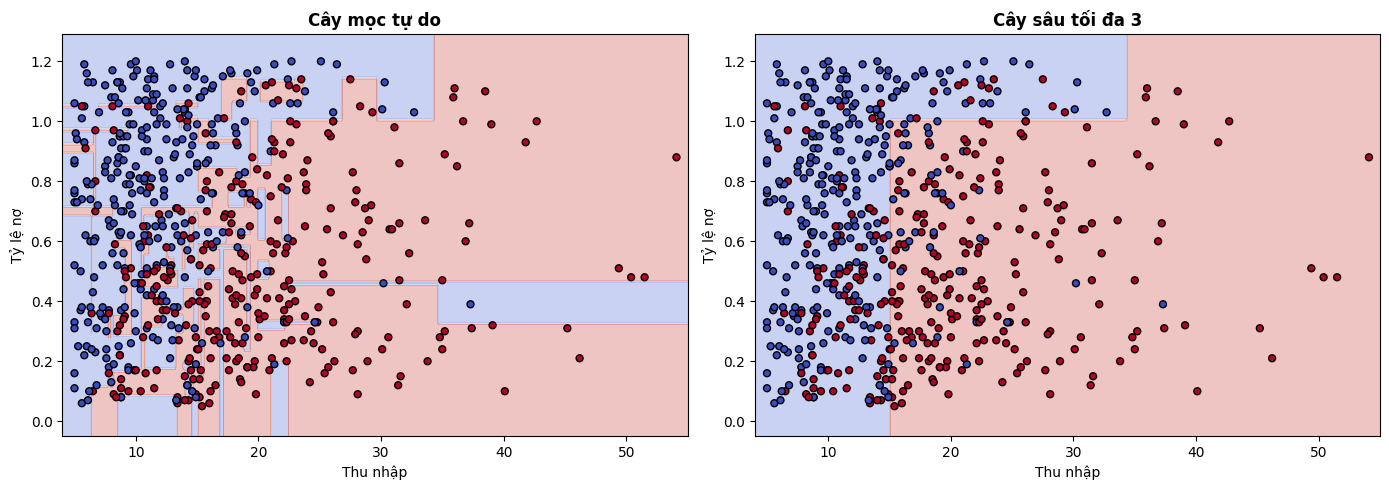

In [14]:
# -*- coding: utf-8 -*-
"""Vẽ ranh giới quyết định cho Cây quyết định (Decision Boundaries)"""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

# 1. Đọc dữ liệu và chọn 2 đặc trưng (thu_nhap, ty_le_no) để vẽ biểu đồ 2D
df = pd.read_csv("khach_vay.csv")
X = df[["thu_nhap", "ty_le_no"]].values
y = df["tra_dung_han"].values

# 2. Khởi tạo 2 mô hình
# - Cây mọc tự do (không giới hạn độ sâu)
model_tu_do = DecisionTreeClassifier(random_state=0)
model_tu_do.fit(X, y)

# - Cây giới hạn độ sâu tối đa là 3
model_depth3 = DecisionTreeClassifier(max_depth=3, random_state=0)
model_depth3.fit(X, y)

# 3. Tạo lưới điểm để vẽ ranh giới quyết định
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.01)
)

# 4. Vẽ biểu đồ so sánh 2 mô hình
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [(model_tu_do, "Cây mọc tự do"), (model_depth3, "Cây sâu tối đa 3")]

for idx, (model, title) in enumerate(models):
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[idx].contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    axes[idx].scatter(
        X[:, 0], X[:, 1], c=y, edgecolors="k", cmap=plt.cm.coolwarm, s=25
    )
    axes[idx].set_title(title, fontweight="bold")
    axes[idx].set_xlabel("Thu nhập")
    axes[idx].set_ylabel("Tỷ lệ nợ")

plt.tight_layout()
plt.show()

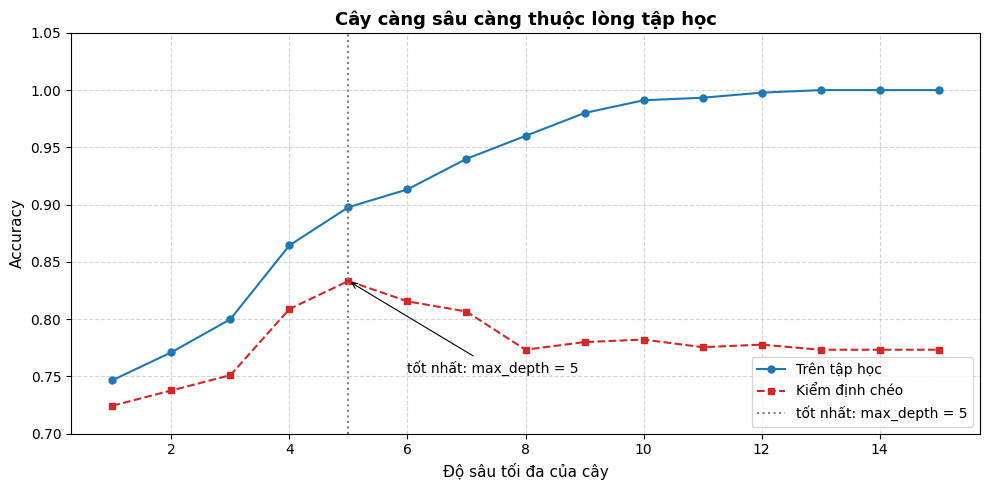

In [15]:
# -*- coding: utf-8 -*-
"""Vẽ đồ thị Accuracy trên tập học và kiểm định chéo theo độ sâu của cây."""

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

# 1. Đọc và chia dữ liệu
df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# 2. Chạy vòng lặp từ độ sâu 1 đến 15 để tính Accuracy
depths = range(1, 16)
train_scores = []
cv_scores = []

for d in depths:
  mh = DecisionTreeClassifier(max_depth=d, random_state=0)
  mh.fit(X_tr, y_tr)

  # Độ chính xác trên tập học
  hoc = accuracy_score(y_tr, mh.predict(X_tr))
  train_scores.append(hoc)

  # Điểm kiểm định chéo trên tập học (cv=5)
  cv_mean = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
  cv_scores.append(cv_mean)

# 3. Vẽ biểu đồ
plt.figure(figsize=(10, 5))
plt.plot(
    depths,
    train_scores,
    marker="o",
    markersize=5,
    color="#1f77b4",
    label="Trên tập học",
)
plt.plot(
    depths,
    cv_scores,
    marker="s",
    markersize=5,
    color="#d62728",
    linestyle="--",
    label="Kiểm định chéo",
)

# Đánh dấu điểm tốt nhất (max_depth = 5)
best_depth = 5
best_cv = cv_scores[depths.index(best_depth)]
plt.axvline(
    x=best_depth, color="gray", linestyle=":", label="tốt nhất: max_depth = 5"
)
plt.annotate(
    "tốt nhất: max_depth = 5",
    xy=(best_depth, best_cv),
    xytext=(best_depth + 1, best_cv - 0.08),
    arrowprops=dict(facecolor="black", arrowstyle="->", lw=0.8),
    fontsize=10,
)

plt.title("Cây càng sâu càng thuộc lòng tập học", fontsize=13, fontweight="bold")
plt.xlabel("Độ sâu tối đa của cây", fontsize=11)
plt.ylabel("Accuracy", fontsize=11)
plt.ylim(0.7, 1.05)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [17]:
# -*- coding: utf-8 -*-
"""Bước 4: kiểm chứng cây không cần chuẩn hoá dữ liệu."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Đọc dữ liệu từ thư mục gốc
df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def cay_sau_5():
  return DecisionTreeClassifier(max_depth=5, random_state=0)


# Cây 1: dữ liệu gốc
goc = cay_sau_5().fit(X_tr, y_tr)
du_goc = goc.predict(X_te)

# Cây 2: dữ liệu đã chuẩn hoá, trung bình tính trên riêng tập học
sc = StandardScaler().fit(X_tr)
chuan = cay_sau_5().fit(sc.transform(X_tr), y_tr)
du_chuan = chuan.predict(sc.transform(X_te))

# Cây 3: đổi thu nhập từ triệu đồng sang nghìn đồng
X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
X_tr_n["thu_nhap"] = X_tr_n["thu_nhap"] * 1000
X_te_n["thu_nhap"] = X_te_n["thu_nhap"] * 1000
nghin = cay_sau_5().fit(X_tr_n, y_tr)
du_nghin = nghin.predict(X_te_n)

print("Accuracy tren tap kiem tra")
print(f"  du lieu goc        : {accuracy_score(y_te, du_goc):.4f}")
print(f"  da chuan hoa      : {accuracy_score(y_te, du_chuan):.4f}")
print(f"  thu nhap nghin dong: {accuracy_score(y_te, du_nghin):.4f}")
print()

print("So khach bi doan khac cay goc")
print(f"  da chuan hoa      : {(du_chuan != du_goc).sum()}")
print(f"  thu nhap nghin dong: {(du_nghin != du_goc).sum()}")
print()

print("Ngưỡng của câu hỏi gốc")
print(f"  du lieu goc        : {goc.tree_.threshold[0]:.2f}")
print(f"  thu nhap nghin dong: {nghin.tree_.threshold[0]:.2f}")

Accuracy tren tap kiem tra
  du lieu goc        : 0.8533
  da chuan hoa      : 0.8533
  thu nhap nghin dong: 0.8533

So khach bi doan khac cay goc
  da chuan hoa      : 0
  thu nhap nghin dong: 0

Ngưỡng của câu hỏi gốc
  du lieu goc        : 15.05
  thu nhap nghin dong: 15050.00


In [22]:
# -*- coding: utf-8 -*-
"""Bước 5: trồng rừng ngẫu nhiên và so với một cây."""

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Đọc và chia dữ liệu
df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Bốc mẫu có hoàn lại: rút 450 lần từ 450 khách
rng = np.random.default_rng(0)
n = len(X_tr)
chi_so = rng.integers(0, n, n)
khac = len(np.unique(chi_so))
print(f"Boc {n} lan, co {khac} khach khac nhau ({khac / n:.0%})")
print()

# Huấn luyện Rừng ngẫu nhiên với 200 cây
rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
print("Rung 200 cay")
print(f"  tap hoc    : {accuracy_score(y_tr, rung.predict(X_tr)):.4f}")
print(f"  tap kiem tra : {accuracy_score(y_te, rung.predict(X_te)):.4f}")
print()

# Khảo sát số cây và độ chính xác trên tập kiểm tra
print("So cay    accuracy tap kiem tra")
for m in [1, 10, 50, 200, 400]:
  r = RandomForestClassifier(n_estimators=m, random_state=0)
  r.fit(X_tr, y_tr)
  print(f"{m:4d}      {accuracy_score(y_te, r.predict(X_te)):.4f}")
print()

# Bảng tổng kết ba mô hình trên cùng tập kiểm tra
ba_mo_hinh = {
    "Cay moc tu do": DecisionTreeClassifier(random_state=0),
    "Cay sau 5": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Rung 200 cay": rung,
}

print("Mo hinh          tap hoc    tap kiem tra")
for ten, mh in ba_mo_hinh.items():
  mh.fit(X_tr, y_tr)
  a = accuracy_score(y_tr, mh.predict(X_tr))
  b = accuracy_score(y_te, mh.predict(X_te))
  print(f"{ten:14s}    {a:.4f}      {b:.4f}")

Boc 450 lan, co 286 khach khac nhau (64%)

Rung 200 cay
  tap hoc    : 1.0000
  tap kiem tra : 0.9000

So cay    accuracy tap kiem tra
   1      0.7933
  10      0.8467
  50      0.8733
 200      0.9000
 400      0.9000

Mo hinh          tap hoc    tap kiem tra
Cay moc tu do     1.0000      0.7667
Cay sau 5         0.8978      0.8533
Rung 200 cay      1.0000      0.9000


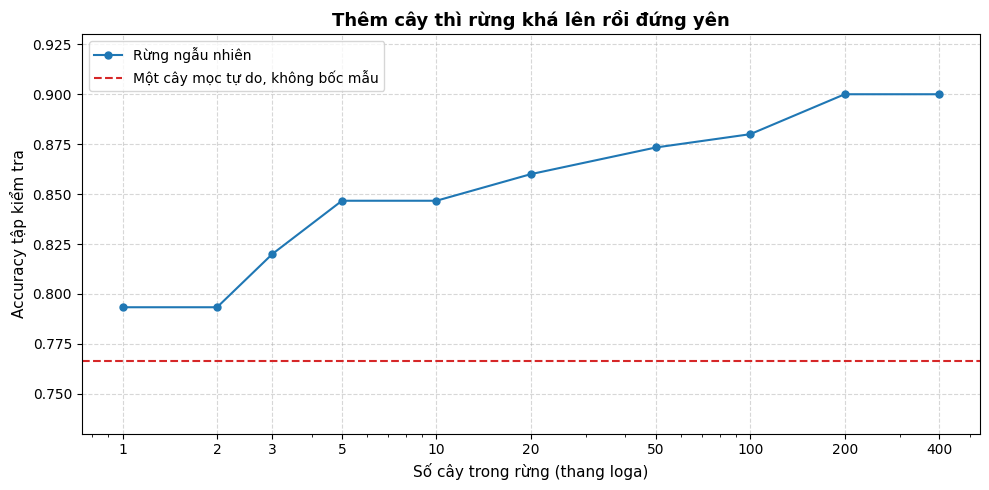

In [27]:
# -*- coding: utf-8 -*-
"""Vẽ đồ thị Hình 5: Accuracy trên tập kiểm tra theo số cây trong rừng."""

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 1. Đọc và chia dữ liệu
df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# 2. Tính accuracy của một cây mọc tự do (đường nét đứt)
single_tree = DecisionTreeClassifier(random_state=0)
single_tree.fit(X_tr, y_tr)
single_acc = accuracy_score(y_te, single_tree.predict(X_te))

# 3. Tính accuracy của rừng ngẫu nhiên theo danh sách số cây
n_estimators_list = [1, 2, 3, 5, 10, 20, 50, 100, 200, 400]
rf_accs = []
for m in n_estimators_list:
  rf = RandomForestClassifier(n_estimators=m, random_state=0)
  rf.fit(X_tr, y_tr)
  rf_accs.append(accuracy_score(y_te, rf.predict(X_te)))

# 4. Vẽ biểu đồ (Hình 5)
plt.figure(figsize=(10, 5))
plt.plot(
    n_estimators_list,
    rf_accs,
    marker="o",
    markersize=5,
    color="#1f77b4",
    label="Rừng ngẫu nhiên",
)
plt.axhline(
    y=single_acc,
    color="#d62728",
    linestyle="--",
    linewidth=1.5,
    label="Một cây mọc tự do, không bốc mẫu",
)

plt.xscale("log")
plt.xticks(n_estimators_list, labels=n_estimators_list)
plt.title(
    "Thêm cây thì rừng khá lên rồi đứng yên", fontsize=13, fontweight="bold"
)
plt.xlabel("Số cây trong rừng (thang loga)", fontsize=11)
plt.ylabel("Accuracy tập kiểm tra", fontsize=11)
plt.ylim(0.73, 0.93)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

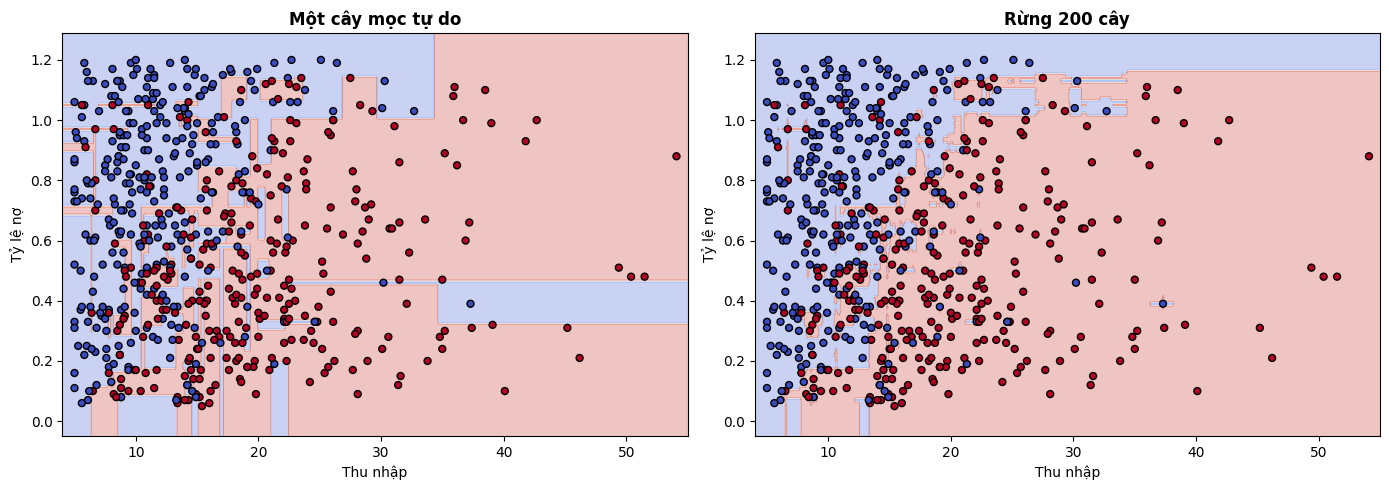

In [29]:
# -*- coding: utf-8 -*-
"""Vẽ biên quyết định: Một cây mọc tự do và Rừng 200 cây."""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# 1. Đọc dữ liệu và chọn 2 đặc trưng (thu_nhap, ty_le_no) để vẽ biểu đồ 2D
df = pd.read_csv("khach_vay.csv")
X = df[["thu_nhap", "ty_le_no"]].values
y = df["tra_dung_han"].values

# 2. Khởi tạo và huấn luyện 2 mô hình
# - Mô hình 1: Một cây mọc tự do (không giới hạn độ sâu)
cay_tu_do = DecisionTreeClassifier(random_state=0)
cay_tu_do.fit(X, y)

# - Mô hình 2: Rừng ngẫu nhiên 200 cây
rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X, y)

# 3. Tạo lưới điểm để vẽ ranh giới quyết định
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 0.1, X[:, 1].max() + 0.1
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.01)
)

# 4. Vẽ biểu đồ so sánh 2 mô hình (Hình 6)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
models = [
    (cay_tu_do, "Một cây mọc tự do"),
    (rung, "Rừng 200 cây"),
]

for idx, (model, title) in enumerate(models):
  Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
  Z = Z.reshape(xx.shape)

  axes[idx].contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
  axes[idx].scatter(
      X[:, 0], X[:, 1], c=y, edgecolors="k", cmap=plt.cm.coolwarm, s=25
  )
  axes[idx].set_title(title, fontsize=12, fontweight="bold")
  axes[idx].set_xlabel("Thu nhập", fontsize=10)
  axes[idx].set_ylabel("Tỷ lệ nợ", fontsize=10)

plt.tight_layout()
plt.show()

In [35]:

# -*- coding: utf-8 -*-
"""Bước 6: Đọc độ quan trọng của đặc trưng."""

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 1. Đọc và chia dữ liệu
df = pd.read_csv("khach_vay.csv")

X = df.drop(columns=["tra_dung_han"])
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

# 2. Đọc độ quan trọng của các đặc trưng
rung = RandomForestClassifier(
    n_estimators=200,
    random_state=0
)

rung.fit(X_tr, y_tr)

qt = pd.Series(
    rung.feature_importances_,
    index=X.columns
)

print("Do quan trong cua bon cot that:")
print(qt.sort_values(ascending=False).round(3).to_string())
print("Tong:", round(qt.sum(), 3))
print()

# 3. Thêm một cột số ngẫu nhiên
rng = np.random.default_rng(0)

X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))

rung_nn = RandomForestClassifier(
    n_estimators=200,
    random_state=0
)

rung_nn.fit(X_tr_nn, y_tr)

qt_nn = pd.Series(
    rung_nn.feature_importances_,
    index=X_tr_nn.columns
)

print("Do quan trong khi them cot ngau nhien:")
print(qt_nn.sort_values(ascending=False).round(3).to_string())


Do quan trong cua bon cot that:
thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088
Tong: 1.0

Do quan trong khi them cot ngau nhien:
thu_nhap              0.427
ty_le_no              0.270
so_ngau_nhien         0.150
co_viec_on_dinh       0.077
so_nguoi_phu_thuoc    0.076


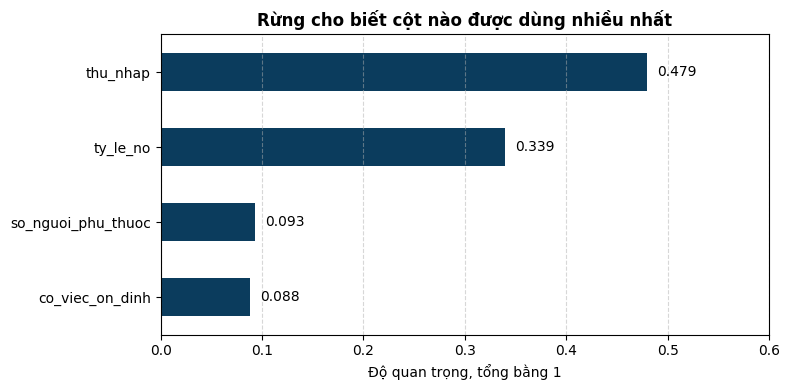

In [36]:
# -*- coding: utf-8 -*-
"""Vẽ biểu đồ Hình 7: Độ quan trọng của các đặc trưng."""

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 1. Đọc và chia dữ liệu
df = pd.read_csv("khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# 2. Huấn luyện Rừng ngẫu nhiên và tính độ quan trọng
rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
qt = pd.Series(rung.feature_importances_, index=X.columns).sort_values()

# 3. Vẽ biểu đồ cột ngang (Hình 7)
plt.figure(figsize=(8, 4))
qt.plot(kind="barh", color="#0b3c5d")
plt.title(
    "Rừng cho biết cột nào được dùng nhiều nhất", fontsize=12, fontweight="bold"
)
plt.xlabel("Độ quan trọng, tổng bằng 1", fontsize=10)
plt.xlim(0, 0.6)

# Thêm nhãn giá trị vào từng cột
for index, value in enumerate(qt):
  plt.text(value + 0.01, index, f"{value:.3f}", va="center", fontsize=10)

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [39]:

# -*- coding: utf-8 -*-
"""Bước 7: Cây quyết định hồi quy trên dữ liệu giá nhà."""

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

# 1. Đọc dữ liệu
df = pd.read_csv("gia_nha.csv")

X = df[["dien_tich"]]
y = df["gia"]

# 2. Chia dữ liệu
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Huấn luyện mô hình
cay = DecisionTreeRegressor(max_depth=3, random_state=0)
cay.fit(X_tr, y_tr)

duong = LinearRegression()
duong.fit(X_tr, y_tr)

# 4. In cấu trúc cây
print("Cay hoi quy co", cay.get_n_leaves(), "la")
print(export_text(cay, feature_names=["dien_tich"], decimals=1))
print()

# 5. Đánh giá sai số MAE
mae_cay = mean_absolute_error(y_te, cay.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))

print("MAE tren tap kiem tra (ty dong):")
print(f"Cay hoi quy: {mae_cay:.4f}")
print(f"Hoi quy tuyen tinh: {mae_duong:.4f}")
print()

# 6. Dự đoán giá nhà mới
can_moi = pd.DataFrame({
    "dien_tich": [60.0, 100.0, 150.0, 250.0]
})

gia_cay = cay.predict(can_moi)
gia_duong = duong.predict(can_moi)

print("Du doan gia nha (ty dong):")
print(f"{'Dien tich':>10} {'Cay':>10} {'Duong thang':>15}")

for dt, a, b in zip(can_moi["dien_tich"], gia_cay, gia_duong):
    print(f"{dt:10.1f} {a:10.2f} {b:15.2f}")


Cay hoi quy co 8 la
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]


MAE tren tap kiem tra (ty dong):
Cay hoi quy: 0.5039
Hoi quy tuyen tinh: 0.2578

Du doan gia nha (ty dong):
 Dien tich        Cay     Duong thang
      60.0       4.92            5.12
     100.0       8.32            8.24
     150.0       9.40           12.13
     250.0       9.40           19.91


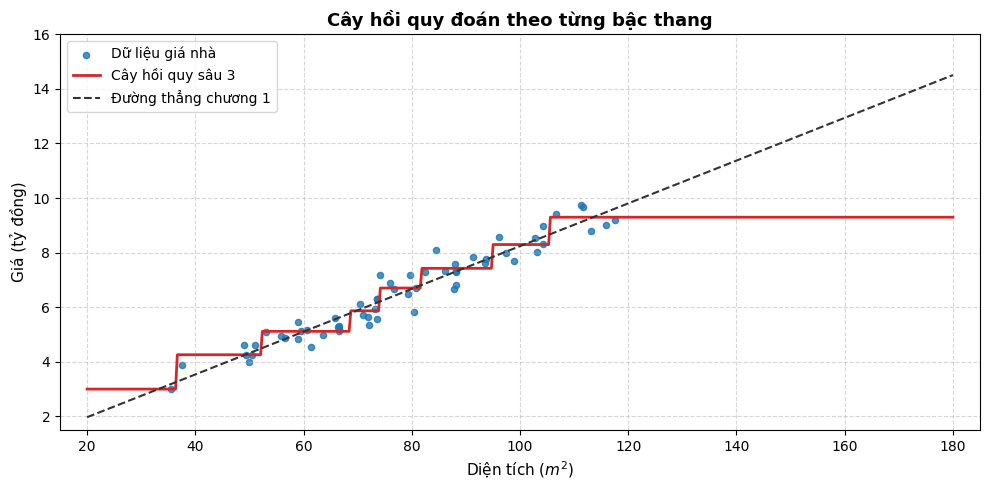

In [40]:
# -*- coding: utf-8 -*-
"""Vẽ đồ thị Hình 8: Đường dự đoán của cây hồi quy sâu 3 và đường thẳng."""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# 1. Đọc dữ liệu
df = pd.read_csv("gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# 2. Huấn luyện mô hình
cay = DecisionTreeRegressor(max_depth=3, random_state=0)
cay.fit(X, y)
duong = LinearRegression().fit(X, y)

# 3. Tạo dải giá trị diện tích mịn để vẽ đường dự đoán dạng bậc thang
X_plot = pd.DataFrame({"dien_tich": np.linspace(20, 180, 500)})
y_cay_plot = cay.predict(X_plot)
y_duong_plot = duong.predict(X_plot)

# 4. Vẽ biểu đồ (Hình 8)
plt.figure(figsize=(10, 5))
plt.scatter(
    X,
    y,
    color="#1f77b4",
    s=20,
    alpha=0.8,
    label="Dữ liệu giá nhà",
)
plt.plot(
    X_plot,
    y_cay_plot,
    color="#d62728",
    linewidth=2,
    label="Cây hồi quy sâu 3",
)
plt.plot(
    X_plot,
    y_duong_plot,
    color="#333333",
    linestyle="--",
    linewidth=1.5,
    label="Đường thẳng chương 1",
)

plt.title(
    "Cây hồi quy đoán theo từng bậc thang", fontsize=13, fontweight="bold"
)
plt.xlabel("Diện tích ($m^2$)", fontsize=11)
plt.ylabel("Giá (tỷ đồng)", fontsize=11)
plt.xlim(15, 185)
plt.ylim(1.5, 16)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'baitap05/cay_nam_la.png'

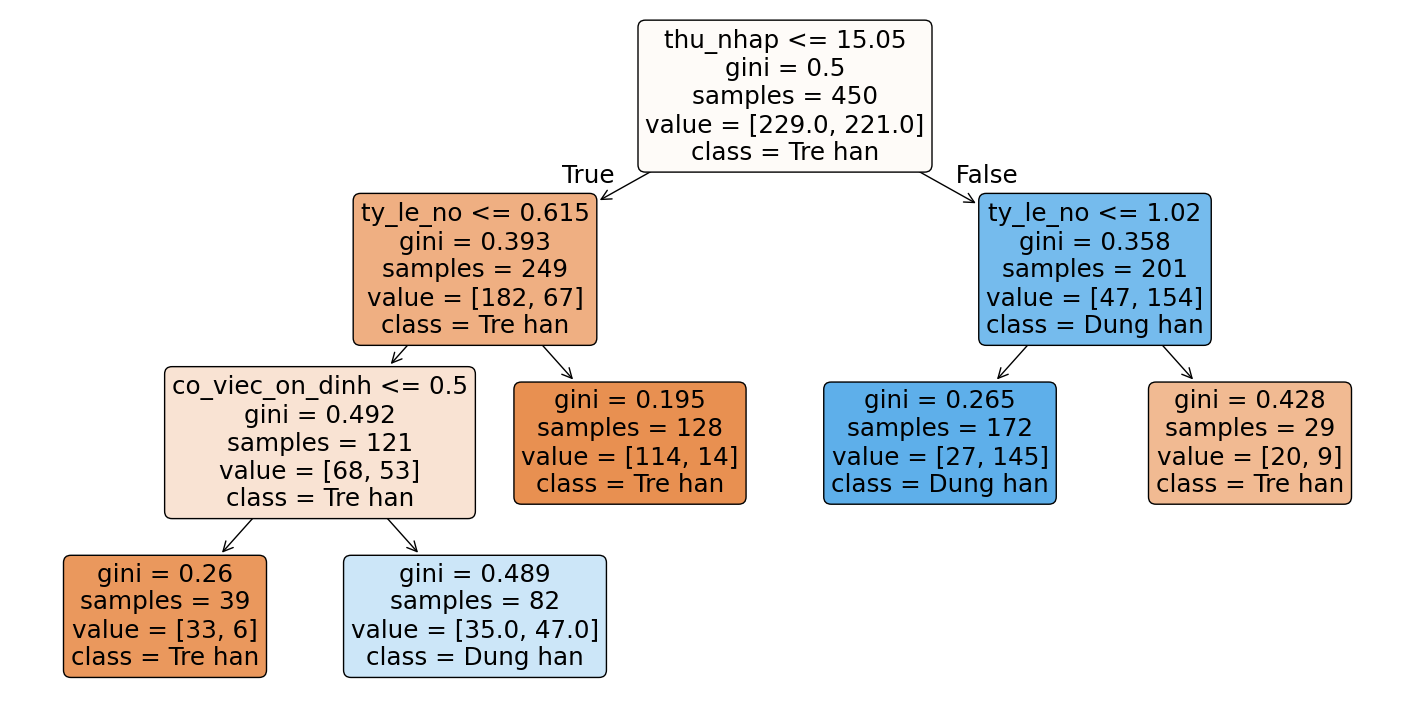

In [46]:
# -*- coding: utf-8 -*-
"""Bài tập 1: Tự vẽ cây quyết định."""

import os
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Tự động tạo thư mục 'data' và di chuyển tệp vào nếu chạy trên Colab
os.makedirs("data", exist_ok=True)
for file_name in ["khach_vay.csv", "gia_nha.csv"]:
  if os.path.exists(file_name) and not os.path.exists(
      os.path.join("data", file_name)
  ):
    os.rename(file_name, os.path.join("data", file_name))

# 1. Đọc và chia dữ liệu
df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# 2. Cây có tối đa 5 lá (max_leaf_nodes=5)
cay_5_la = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay_5_la.fit(X_tr, y_tr)

plt.figure(figsize=(18, 9))
plot_tree(
    cay_5_la,
    feature_names=X.columns,
    class_names=["Tre han", "Dung han"],
    filled=True,
    rounded=True,
)
plt.savefig("baitap05/cay_nam_la.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Cây sâu tối đa 2 (max_depth=2)
cay_sau_2 = DecisionTreeClassifier(max_depth=2, random_state=0)
cay_sau_2.fit(X_tr, y_tr)

plt.figure(figsize=(14, 7))
plot_tree(
    cay_sau_2,
    feature_names=X.columns,
    class_names=["Tre han", "Dung han"],
    filled=True,
    rounded=True,
)
plt.show()

print("Số lá của cây 5 lá:", cay_5_la.get_n_leaves())
print("Số lá của cây sâu 2:", cay_sau_2.get_n_leaves())

In [47]:
# -*- coding: utf-8 -*-
"""Bài tập 2: Tự tìm câu hỏi gốc trên dữ liệu thật."""

import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Tự động tạo thư mục 'data' và chuyển tệp vào nếu chạy trên Colab
os.makedirs("data", exist_ok=True)
for file_name in ["khach_vay.csv", "gia_nha.csv"]:
  if os.path.exists(file_name) and not os.path.exists(
      os.path.join("data", file_name)
  ):
    os.rename(file_name, os.path.join("data", file_name))

# 1. Đọc và chia dữ liệu chuẩn xác (450 mẫu cho tập học)
df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def tinh_gini(y_subset):
  """Tính độ tạp chất Gini của một tập nhãn."""
  if len(y_subset) == 0:
    return 0
  p = y_subset.mean()
  return 1 - (p**2 + (1 - p) ** 2)


def tim_cau_hoi(X_data, y_data):
  """Thử mọi cột và mọi ngưỡng để tìm câu hỏi làm Gini giảm nhiều nhất."""
  best_gain = -1
  best_col = None
  best_val = None
  n = len(y_data)
  current_gini = tinh_gini(y_data)

  for col in X_data.columns:
    values = sorted(X_data[col].unique())
    for i in range(len(values) - 1):
      threshold = (values[i] + values[i + 1]) / 2
      mask = X_data[col] <= threshold
      y_left = y_data[mask]
      y_right = y_data[~mask]

      # Tính Gini trung bình có trọng số sau khi chia nhánh
      gini_split = (len(y_left) / n) * tinh_gini(y_left) + (
          len(y_right) / n
      ) * tinh_gini(y_right)
      gain = current_gini - gini_split

      if gain > best_gain:
        best_gain = gain
        best_col = col
        best_val = threshold

  return best_col, best_val, best_gain


# 2. Chạy hàm trên 450 khách của tập học (X_tr, y_tr)
col, val, gain = tim_cau_hoi(X_tr, y_tr)
print(f"Cột tốt nhất : {col}")
print(f"Ngưỡng tối ưu: {val:.2f}")
print(f"Độ giảm Gini : {gain:.4f}")

Cột tốt nhất : thu_nhap
Ngưỡng tối ưu: 15.05
Độ giảm Gini : 0.1221


In [48]:
# -*- coding: utf-8 -*-
"""Bài tập 3: So sánh giữa Gini và Entropy."""

import os
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier

# Tự động tạo thư mục 'data' và chuyển tệp vào nếu chạy trên Colab
os.makedirs("data", exist_ok=True)
for file_name in ["khach_vay.csv", "gia_nha.csv"]:
  if os.path.exists(file_name) and not os.path.exists(
      os.path.join("data", file_name)
  ):
    os.rename(file_name, os.path.join("data", file_name))

# 1. Đọc và chia dữ liệu chuẩn xác
df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# 2. Tìm độ sâu tốt nhất bằng kiểm định chéo 5 phần với criterion="entropy"
params = {"max_depth": range(1, 11)}
clf = DecisionTreeClassifier(criterion="entropy", random_state=0)
grid = GridSearchCV(clf, params, cv=5, scoring="accuracy")
grid.fit(X_tr, y_tr)

best_depth = grid.best_params_["max_depth"]
best_model = grid.best_estimator_
acc = accuracy_score(y_te, best_model.predict(X_te))

# 3. In kết quả
print(f"Độ sâu tốt nhất (Entropy): {best_depth}")
print(f"Accuracy tập kiểm tra (Entropy): {acc:.4f}")

Độ sâu tốt nhất (Entropy): 5
Accuracy tập kiểm tra (Entropy): 0.8467


In [49]:
# -*- coding: utf-8 -*-
"""Bài tập 4: Cắt tỉa cây bằng min_samples_leaf."""

import os
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeClassifier

# Tự động tạo thư mục 'data' và chuyển tệp vào nếu chạy trên Colab
os.makedirs("data", exist_ok=True)
for file_name in ["khach_vay.csv", "gia_nha.csv"]:
  if os.path.exists(file_name) and not os.path.exists(
      os.path.join("data", file_name)
  ):
    os.rename(file_name, os.path.join("data", file_name))

# 1. Đọc và chia dữ liệu chuẩn xác
df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# 2. Tìm min_samples_leaf tốt nhất qua kiểm định chéo 5 phần
params = {"min_samples_leaf": [1, 2, 5, 10, 20, 40]}
clf = DecisionTreeClassifier(max_depth=None, random_state=0)
grid = GridSearchCV(clf, params, cv=5, scoring="accuracy")
grid.fit(X_tr, y_tr)

best_min_samples = grid.best_params_["min_samples_leaf"]
best_model = grid.best_estimator_
acc = accuracy_score(y_te, best_model.predict(X_te))

# 3. In kết quả
print(f"min_samples_leaf tốt nhất: {best_min_samples}")
print(f"Accuracy trên tập kiểm tra: {acc:.4f}")

min_samples_leaf tốt nhất: 10
Accuracy trên tập kiểm tra: 0.8467


In [50]:
# -*- coding: utf-8 -*-
"""Bài tập 5: Độ quan trọng của đặc trưng bằng phương pháp xáo trộn."""

import os
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

# Tự động tạo thư mục 'data' và chuyển tệp vào nếu chạy trên Colab
os.makedirs("data", exist_ok=True)
for file_name in ["khach_vay.csv", "gia_nha.csv"]:
  if os.path.exists(file_name) and not os.path.exists(
      os.path.join("data", file_name)
  ):
    os.rename(file_name, os.path.join("data", file_name))

# 1. Đọc và chia dữ liệu chuẩn xác
df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# 2. Thêm một cột ngẫu nhiên vào cả tập học và tập kiểm tra
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))

X_te_nn = X_te.copy()
X_te_nn["so_ngau_nhien"] = rng.random(len(X_te))

# 3. Huấn luyện mô hình Rừng ngẫu nhiên (200 cây)
rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr_nn, y_tr)

# 4. Tính độ quan trọng bằng phương pháp xáo trộn (Permutation Importance) trên tập kiểm tra
result = permutation_importance(
    rung, X_te_nn, y_te, n_repeats=20, random_state=0
)
importances = pd.Series(result.importances_mean, index=X_tr_nn.columns)

print("Độ quan trọng trung bình của 5 cột (Permutation Importance):")
print(importances.sort_values(ascending=False).round(4).to_string())

Độ quan trọng trung bình của 5 cột (Permutation Importance):
thu_nhap              0.3073
ty_le_no              0.1993
co_viec_on_dinh       0.1117
so_nguoi_phu_thuoc    0.0497
so_ngau_nhien         0.0017


In [51]:
# -*- coding: utf-8 -*-
"""Bài tập 6: Rừng ngẫu nhiên cho bài toán hồi quy giá nhà."""

import os
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

# Tự động tạo thư mục 'data' và chuyển tệp vào nếu chạy trên Colab
os.makedirs("data", exist_ok=True)
for file_name in ["khach_vay.csv", "gia_nha.csv"]:
  if os.path.exists(file_name) and not os.path.exists(
      os.path.join("data", file_name)
  ):
    os.rename(file_name, os.path.join("data", file_name))

# 1. Đọc và chia dữ liệu giá nhà (giống cách chia ở mục 8)
df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Huấn luyện các mô hình: Rừng 200 cây, Cây sâu 3 và Hồi quy tuyến tính
rf_reg = RandomForestRegressor(n_estimators=200, random_state=0)
rf_reg.fit(X_tr, y_tr)

cay = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

# 3. So sánh sai số MAE trên tập kiểm tra
mae_rf = mean_absolute_error(y_te, rf_reg.predict(X_te))
mae_cay = mean_absolute_error(y_te, cay.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))

print("Sai số MAE trên tập kiểm tra (tỷ đồng):")
print(f"  Rừng 200 cây : {mae_rf:.4f}")
print(f"  Cây sâu 3    : {mae_cay:.4f}")
print(f"  Đường thẳng  : {mae_duong:.4f}")
print()

# 4. Dự đoán giá căn nhà 250 m2
can_250 = pd.DataFrame({"dien_tich": [250.0]})
du_doan_250 = rf_reg.predict(can_250)[0]
print(f"Dự đoán giá căn 250 m2 bằng Rừng: {du_doan_250:.2f} tỷ đồng")

Sai số MAE trên tập kiểm tra (tỷ đồng):
  Rừng 200 cây : 0.4559
  Cây sâu 3    : 0.5039
  Đường thẳng  : 0.2578

Dự đoán giá căn 250 m2 bằng Rừng: 9.20 tỷ đồng
